# Data Preparation 5: Analysis

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

## 1. Analyze Lifetime

In [3]:
# use the output of DataPrep 3 
debris_df = pd.read_csv('../Data/Combined.csv')

In [4]:
# check datatypes
print(debris_df.dtypes)

NORAD_CAT_ID            int64
INTLDES                object
SATNAME                object
OBJECT_TYPE            object
COUNTRY                object
SITE                   object
LAUNCH                 object
DECAY                  object
EPOCH                  object
DAYS_SINCE_LAUNCH       int64
PERIAPSIS             float64
APOAPSIS              float64
ARG_OF_PERICENTER     float64
MEAN_MOTION           float64
ECCENTRICITY          float64
INCLINATION           float64
RA_OF_ASC_NODE        float64
MEAN_ANOMALY          float64
REV_AT_EPOCH          float64
BSTAR                 float64
MEAN_MOTION_DOT       float64
MEAN_MOTION_DDOT      float64
SEMIMAJOR_AXIS        float64
PERIOD                float64
REMAINING_LIFETIME      int64
LIFETIME                int64
dtype: object


In [5]:
# summary statistics of lifetime
print(debris_df['LIFETIME'].describe())

count    23022.000000
mean      3553.883633
std       4805.247688
min          0.000000
25%         37.000000
50%        945.000000
75%       5817.500000
max      23115.000000
Name: LIFETIME, dtype: float64


In [6]:
# summary statistics of lifetime in years
lifetime_years = debris_df['LIFETIME'] / 365.25 # account for leap years
print(lifetime_years.describe())

count    23022.000000
mean         9.730003
std         13.156051
min          0.000000
25%          0.101300
50%          2.587269
75%         15.927447
max         63.285421
Name: LIFETIME, dtype: float64


Boxplot of lifetime in years:


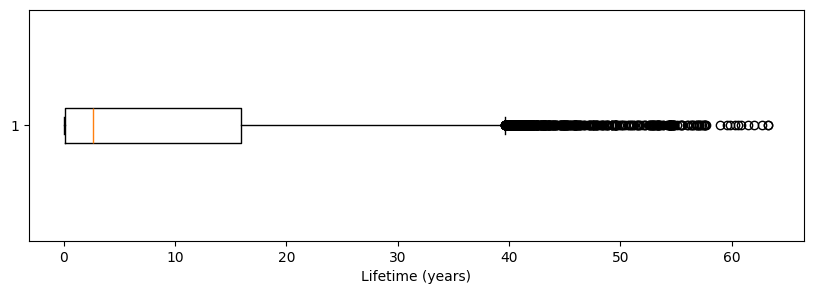

In [7]:
# create a boxplot of the lifetime in years
print('Boxplot of lifetime in years:')
plt.style.use('default')
plt.figure(figsize=(10, 3))
plt.boxplot(debris_df['LIFETIME']/ 365.25, vert=False)
plt.xlabel('Lifetime (years)')
plt.show()


Histogram of lifetime in years:


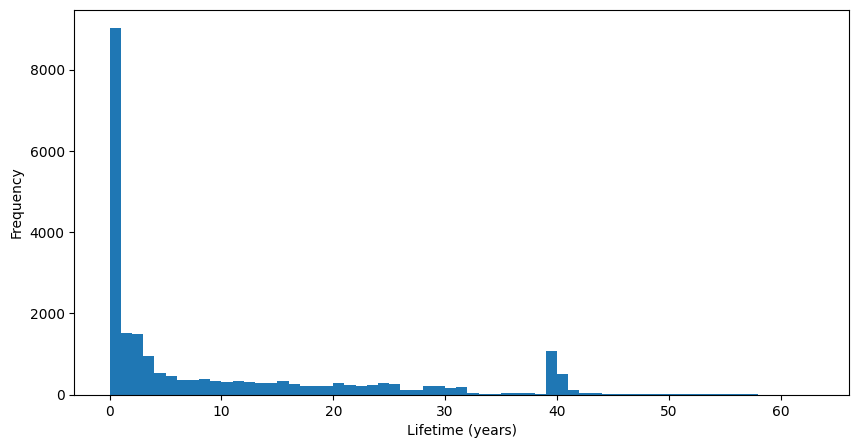

In [8]:
# create histogram of lifetime in years
print('Histogram of lifetime in years:')
plt.figure(figsize=(10, 5))
plt.hist(debris_df['LIFETIME']/365, bins=np.arange(0, max(debris_df['LIFETIME']/365), 1))
plt.xlabel('Lifetime (years)')
plt.ylabel('Frequency')
plt.show()


In [9]:
# calculate how many objects have a lifetime of less / longer or equal to 1 year
print("Objects with lifetime < 1 year: ", debris_df[debris_df['LIFETIME'] < 365].shape[0])
print("Objects with lifetime >= 1 year: ", debris_df[debris_df['LIFETIME'] >= 365].shape[0])  
# calculate how many objects have a lifetime of less / longer or equal to 5 years
print("\nObjects with lifetime < 5 years: ", debris_df[debris_df['LIFETIME'] < 5*365].shape[0])
print("Objects with lifetime >= 5 years: ", debris_df[debris_df['LIFETIME'] >= 5*365].shape[0])
# calculate how many objects have a lifetime of less / longer or equal to 25 years
print("\nObjects with lifetime < 25 years: ", debris_df[debris_df['LIFETIME'] < 25*365].shape[0])
print("Objects with lifetime >= 25 years: ", debris_df[debris_df['LIFETIME'] >= 25*365].shape[0])


Objects with lifetime < 1 year:  9025
Objects with lifetime >= 1 year:  13997

Objects with lifetime < 5 years:  13521
Objects with lifetime >= 5 years:  9501

Objects with lifetime < 25 years:  19495
Objects with lifetime >= 25 years:  3527


It could make sense to drop objects with a lifetime of one year or less but since in this all objects shall be considered, they will stay in the dataset.

Examine Peak around 40 years

In [10]:
# show objects with a lifetime around 40 years (39-41 years -> 14235-14965 days)
peak_df = debris_df[(debris_df['LIFETIME'] > 14235) & (debris_df['LIFETIME'] < 14965)]
peak_df

,NORAD_CAT_ID,INTLDES,SATNAME,OBJECT_TYPE,COUNTRY,SITE,LAUNCH,DECAY,EPOCH,DAYS_SINCE_LAUNCH,...,RA_OF_ASC_NODE,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,REMAINING_LIFETIME,LIFETIME
37,135,1961-015V,THOR ABLESTAR DEB,DEBRIS,US,AFETR,1961-06-29,2002-04-17,2000-08-10,14287,...,279.8185,188.0169,1661.0,0.002605,0.000127,0.000000,7068.486,98.570,615,14902
75,229,1962-002D,DELTA 1 R/B,ROCKET BODY,US,AFETR,1962-02-08,2002-08-10,1994-02-05,11685,...,175.2512,262.3666,69317.0,0.000219,0.000015,0.000000,7007.026,97.288,3108,14793
92,275,1961-015CP,THOR ABLESTAR DEB,DEBRIS,US,AFETR,1961-06-29,2001-12-01,1990-08-20,10644,...,283.9308,113.7098,49955.0,0.001441,0.000042,0.000000,7152.930,100.342,4121,14765
175,462,1961-015EY,THOR ABLESTAR DEB,DEBRIS,US,AFETR,1961-06-29,2001-04-01,1996-02-06,12640,...,322.2091,65.4705,78716.0,0.000120,0.000005,0.000000,7075.750,98.722,1881,14521
264,647,1961-015GY,THOR ABLESTAR DEB,DEBRIS,US,AFETR,1961-06-29,2001-04-30,1994-05-18,12011,...,347.2363,136.4026,71788.0,0.000218,0.000015,0.000000,7021.190,97.583,2539,14550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22307,53099,1982-092CBK,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2022-11-17,2022-09-24,14618,...,166.1193,276.1128,3934.0,0.001847,0.001199,0.000000,6784.586,92.693,54,14672
22388,53585,1982-092CBL,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2023-04-28,2022-08-21,14584,...,207.2347,163.9570,1585.0,0.000582,0.000173,0.000000,6855.805,94.156,250,14834
22424,53952,1982-092CBM,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2022-09-28,2022-09-28,14622,...,161.3900,208.8575,432.0,0.004931,0.027777,0.009035,6641.052,89.767,0,14622
22425,53953,1982-092CBN,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2023-02-23,2022-11-19,14674,...,113.4096,176.2524,1225.0,0.001652,0.000825,0.000000,6805.908,93.130,96,14770


In [11]:
# show most frequent value of Satname, Country and Launch and how many objects in percent have that value
most_frequent_satname = peak_df['SATNAME'].mode()[0]
most_frequent_country = peak_df['COUNTRY'].mode()[0]
most_frequent_launch = peak_df['LAUNCH'].mode()[0]

satname_percentage = (peak_df['SATNAME'].value_counts(normalize=True)[most_frequent_satname] * 100).round(2)
country_percentage = (peak_df['COUNTRY'].value_counts(normalize=True)[most_frequent_country] * 100).round(2)
launch_percentage = (peak_df['LAUNCH'].value_counts(normalize=True)[most_frequent_launch] * 100).round(2)

print("\nMost frequent value of Satname: ", most_frequent_satname, f"({satname_percentage}%)")
print("Most frequent value of Country: ", most_frequent_country, f"({country_percentage}%)")
print("Most frequent value of Launch: ", most_frequent_launch, f"({launch_percentage}%)")


Most frequent value of Satname:  COSMOS 1408 DEB (98.18%)
Most frequent value of Country:  CIS (98.75%)
Most frequent value of Launch:  1982-09-16 (98.18%)


In [15]:
# filter only the COSMOS 1408 Debris objects
cosmos_1408_df = peak_df[peak_df['SATNAME'] == most_frequent_satname]
cosmos_1408_df


,NORAD_CAT_ID,INTLDES,SATNAME,OBJECT_TYPE,COUNTRY,SITE,LAUNCH,DECAY,EPOCH,DAYS_SINCE_LAUNCH,...,RA_OF_ASC_NODE,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,REMAINING_LIFETIME,LIFETIME
20473,49516,1982-092D,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2022-07-04,2022-05-24,14495,...,292.3860,159.8061,2920.0,0.003782,0.003259,0.000000,6765.295,92.297,41,14536
20474,49517,1982-092E,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2022-01-30,2021-12-15,14335,...,93.2886,343.6110,456.0,0.002481,0.000894,0.000000,6835.382,93.735,46,14381
20475,49519,1982-092G,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2022-04-05,2021-12-29,14349,...,79.3195,66.6285,671.0,0.002318,0.000787,0.000000,6840.124,93.833,97,14446
20476,49520,1982-092H,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2022-04-13,2022-02-17,14399,...,28.9510,207.0309,1433.0,0.002744,0.001236,0.000000,6815.748,93.332,55,14454
20477,49521,1982-092J,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2021-12-29,2021-12-18,14338,...,87.3041,200.1911,508.0,0.001344,0.006451,0.000164,6675.971,90.476,11,14349
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22307,53099,1982-092CBK,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2022-11-17,2022-09-24,14618,...,166.1193,276.1128,3934.0,0.001847,0.001199,0.000000,6784.586,92.693,54,14672
22388,53585,1982-092CBL,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2023-04-28,2022-08-21,14584,...,207.2347,163.9570,1585.0,0.000582,0.000173,0.000000,6855.805,94.156,250,14834
22424,53952,1982-092CBM,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2022-09-28,2022-09-28,14622,...,161.3900,208.8575,432.0,0.004931,0.027777,0.009035,6641.052,89.767,0,14622
22425,53953,1982-092CBN,COSMOS 1408 DEB,DEBRIS,CIS,PKMTR,1982-09-16,2023-02-23,2022-11-19,14674,...,113.4096,176.2524,1225.0,0.001652,0.000825,0.000000,6805.908,93.130,96,14770


In [16]:
# show the range of Lifetimes 
print("\nRange of Lifetimes of COSMOS 1408 Debris objects:", cosmos_1408_df['LIFETIME'].min(), "to", cosmos_1408_df['LIFETIME'].max(), "days")
print("Range of Lifetimes of COSMOS 1408 Debris objects:", (cosmos_1408_df['LIFETIME'].min() / 365.25).round(2), "to", (cosmos_1408_df['LIFETIME'].max() / 365.25).round(2), "years")


Range of Lifetimes of COSMOS 1408 Debris objects: 14320 to 14957 days
Range of Lifetimes of COSMOS 1408 Debris objects: 39.21 to 40.95 years


In [22]:
# "real" range of lifetimes: difference between November 15, 2021 and Decay Date
cosmos_1408_df.loc[:, 'DECAY_DIFF'] = (pd.to_datetime(cosmos_1408_df['DECAY']) - pd.Timestamp('2021-11-15')).dt.days
print("\nRange of DECAY_DIFF values of COSMOS 1408 Debris objects:", cosmos_1408_df['DECAY_DIFF'].min(), "to", cosmos_1408_df['DECAY_DIFF'].max(), "days")
print("Range of DECAY_DIFF values of COSMOS 1408 Debris objects:", (cosmos_1408_df['DECAY_DIFF'].min() / 365.25).round(2), "to", (cosmos_1408_df['DECAY_DIFF'].max() / 365.25).round(2), "years")
print("\nMean of DECAY_DIFF values of COSMOS 1408 Debris objects:", (cosmos_1408_df['DECAY_DIFF'].mean().round(2)), "days")
print("Mean of DECAY_DIFF values of COSMOS 1408 Debris objects:", (cosmos_1408_df['DECAY_DIFF'].mean() / 365.25).round(2), "years")



Range of DECAY_DIFF values of COSMOS 1408 Debris objects: 15 to 652 days
Range of DECAY_DIFF values of COSMOS 1408 Debris objects: 0.04 to 1.79 years

Mean of DECAY_DIFF values of COSMOS 1408 Debris objects: 240.92 days
Mean of DECAY_DIFF values of COSMOS 1408 Debris objects: 0.66 years


In [13]:
# show the range of remaining lifetimes
print("\nRange of Remaining Lifetimes of COSMOS 1408 Debris objects:", cosmos_1408_df['REMAINING_LIFETIME'].min(), "to", cosmos_1408_df['REMAINING_LIFETIME'].max(), "days")
print("Range of Remaining Lifetimes of COSMOS 1408 Debris objects:", (cosmos_1408_df['REMAINING_LIFETIME'].min() / 365.25).round(2), "to", (cosmos_1408_df['REMAINING_LIFETIME'].max() / 365.25).round(2), "years")


Range of Remaining Lifetimes of COSMOS 1408 Debris objects: 0 to 600 days
Range of Remaining Lifetimes of COSMOS 1408 Debris objects: 0.0 to 1.64 years


In [14]:
# check whether the epoch is always after Nov 15, 2021 (Date of ASAT test)
print("\nEpochs of COSMOS 1408 Debris objects:")
print(cosmos_1408_df['EPOCH'].min(), "to", cosmos_1408_df['EPOCH'].max())


Epochs of COSMOS 1408 Debris objects:
2021-11-29 to 2023-06-17


## 2. Analyze Remaining Lifetime

In [14]:
# describe
debris_df['REMAINING_LIFETIME'].describe()

count    23022.000000
mean       512.950135
std       1172.968957
min          0.000000
25%          6.000000
50%         52.000000
75%        427.750000
max      15767.000000
Name: REMAINING_LIFETIME, dtype: float64

In [15]:
# summary statistics of remaining lifetime in years
remlifetime_years = debris_df['REMAINING_LIFETIME'] / 365.25 # account for leap years
print(remlifetime_years.describe())

count    23022.000000
mean         1.404381
std          3.211414
min          0.000000
25%          0.016427
50%          0.142368
75%          1.171116
max         43.167693
Name: REMAINING_LIFETIME, dtype: float64


Boxplot of remaining lifetime in years:


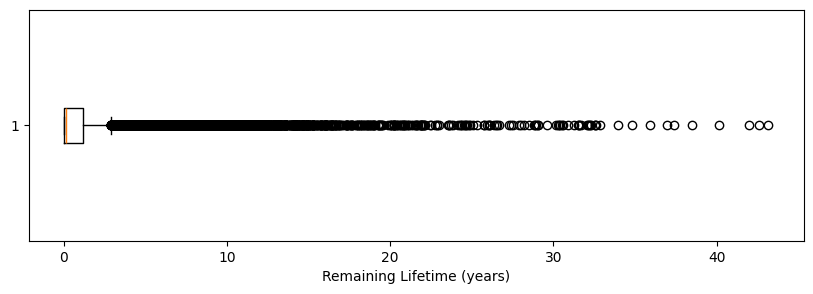

In [16]:
# create a boxplot
print('Boxplot of remaining lifetime in years:')
plt.figure(figsize=(10, 3))
plt.style.use('default')
plt.boxplot(debris_df['REMAINING_LIFETIME']/ 365.25, vert=False)
plt.xlabel('Remaining Lifetime (years)')
plt.show()

Histogram of remaining lifetime in years:


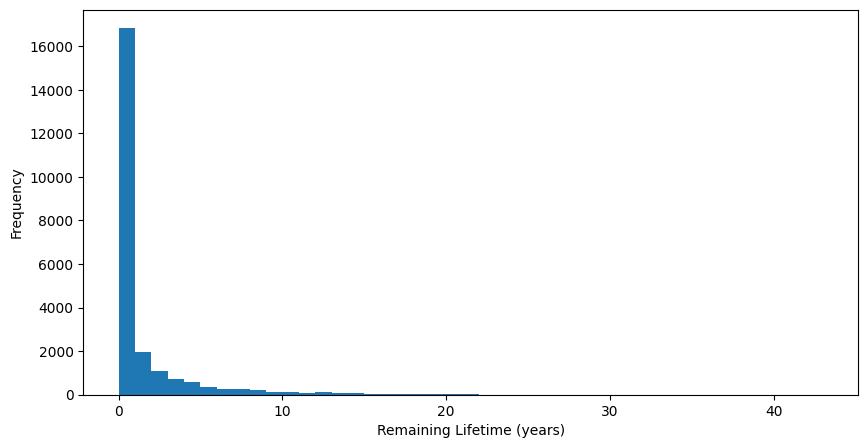

In [17]:
# create histogram of remaining lifetime in years
print('Histogram of remaining lifetime in years:')
plt.figure(figsize=(10, 5))
plt.hist(debris_df['REMAINING_LIFETIME']/365, bins=np.arange(0, max(debris_df['REMAINING_LIFETIME']/365), 1))
plt.xlabel('Remaining Lifetime (years)')
plt.ylabel('Frequency')
plt.show()

In [39]:
# calculate how many objects have a remaining lifetime of less / more than 1 year
print("Objects with remaining lifetime < 1 year: ", debris_df[debris_df['REMAINING_LIFETIME'] < 365].shape[0])
print("Objects with remaining lifetime > 1 year: ", debris_df[debris_df['REMAINING_LIFETIME'] >= 365].shape[0])  
# calculate how many objects have a remaining lifetime of less / more than 5 years
print("\nObjects with remaining lifetime < 5 years: ", debris_df[debris_df['REMAINING_LIFETIME'] < 5*365].shape[0])
print("Objects with remaining lifetime > 5 years: ", debris_df[debris_df['REMAINING_LIFETIME'] >= 5*365].shape[0])
# calculate how many objects have a remaining lifetime of less / more than 25 years
print("\nObjects with remaining lifetime < 25 years: ", debris_df[debris_df['REMAINING_LIFETIME'] < 25*365].shape[0])
print("Objects with remaining lifetime > 25 years: ", debris_df[debris_df['REMAINING_LIFETIME'] >= 25*365].shape[0])


Objects with remaining lifetime < 1 year:  16833
Objects with remaining lifetime > 1 year:  6189

Objects with remaining lifetime < 5 years:  21112
Objects with remaining lifetime > 5 years:  1910

Objects with remaining lifetime < 25 years:  22966
Objects with remaining lifetime > 25 years:  56


Scatter plot of lifetime vs remaining lifetime:


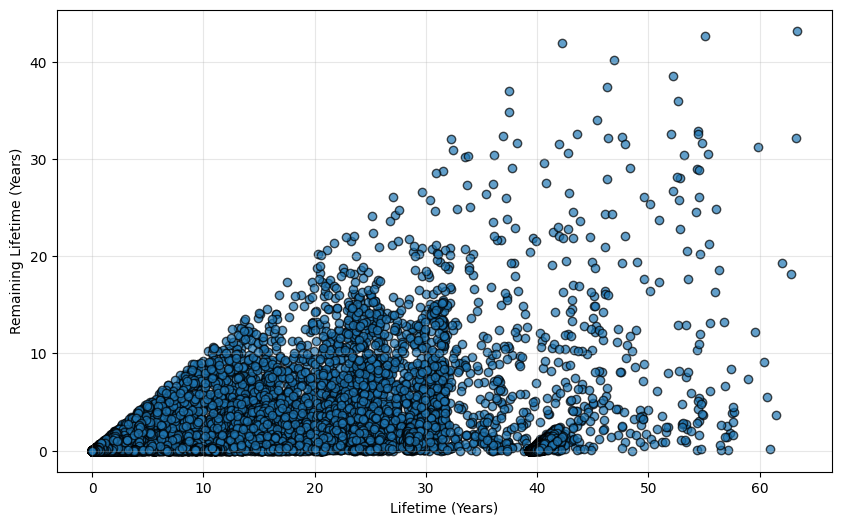

In [20]:
# Create the scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(
    debris_df['LIFETIME'] / 365, 
    debris_df['REMAINING_LIFETIME'] / 365, 
    alpha=0.7, 
    edgecolors='k'
)

# Add labels and title
print('Scatter plot of lifetime vs remaining lifetime:')
plt.xlabel('Lifetime (Years)')
plt.ylabel('Remaining Lifetime (Years)')
plt.grid(True, alpha=0.3)
plt.show()

## 3. Feature Correlation

In [141]:
# use the preprocessed data from the MLP for one hot encoded values (Object Type, Launch Year+Month, Epoch Year+Month)
# normalized or not does not make a difference since Pearson Correlation is not affected by scaling
train_preprocessed_df = pd.read_csv('../Data/ModelInput/TrainPreprocessed.csv')
test_preprocessed_df = pd.read_csv('../Data/ModelInput/TestPreprocessed.csv')

# concat
debrisCorrAll_df = pd.concat([train_preprocessed_df, test_preprocessed_df], axis=0)

In [ ]:
# drop columnns 
columns_to_drop = [col for col in debrisCorrAll_df.columns if col.startswith('COUNTRY') or col.startswith('SITE')]
columns_to_drop += ['NORAD_CAT_ID']
debrisCorr_df = debrisCorrAll_df.drop(columns=columns_to_drop)

In [92]:
# Calculate the correlation matrix
corr_matrix = debrisCorr_df.corr()

Feature correlation heatmap:


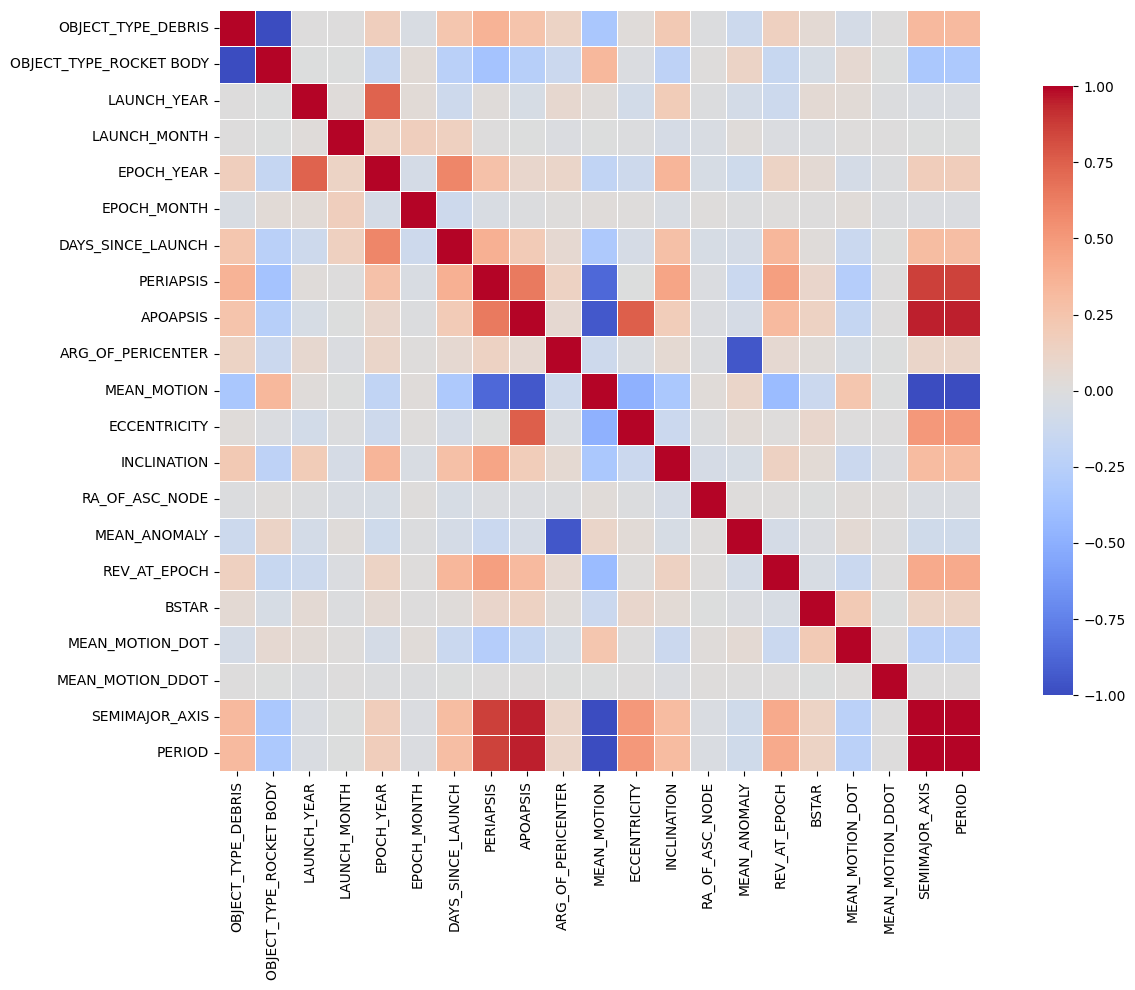

In [93]:
# Heatmap for feature correlation
print('Feature correlation heatmap:')
feature_corr_matrix = corr_matrix.drop(['LIFETIME', 'REMAINING_LIFETIME'], axis=0).drop(['LIFETIME', 'REMAINING_LIFETIME'], axis=1)
plt.style.use('default')
plt.figure(figsize=(14, 10))
sns.heatmap(feature_corr_matrix, annot=False, cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.tight_layout()
plt.show()

In [94]:
# Unstack the correlation matrix and sort by absolute correlation values
sorted_corr = corr_matrix.unstack().sort_values(ascending=False, key=lambda x: x.abs())

# Filter out self-correlations
sorted_corr = sorted_corr[sorted_corr.index.get_level_values(0) != sorted_corr.index.get_level_values(1)]

# Remove duplicate correlations by keeping only one of (A, B) and (B, A)
sorted_corr = sorted_corr.loc[~sorted_corr.index.duplicated(keep='first') & 
                              (sorted_corr.index.get_level_values(0) < sorted_corr.index.get_level_values(1))]
# filter out correlations with LIFETIME and REMAINING_LIFETIME
sorted_corr = sorted_corr[~sorted_corr.index.get_level_values(0).isin(['LIFETIME', 'REMAINING_LIFETIME']) & 
                              ~sorted_corr.index.get_level_values(1).isin(['LIFETIME', 'REMAINING_LIFETIME'])]

# Display the sorted correlations above 0.5
print('Sorted feature correlations:')
sorted_corr[sorted_corr.abs() > 0.5]

Sorted feature correlations:


OBJECT_TYPE_DEBRIS  OBJECT_TYPE_ROCKET BODY   -1.000000
PERIOD              SEMIMAJOR_AXIS             0.999938
MEAN_MOTION         SEMIMAJOR_AXIS            -0.998568
                    PERIOD                    -0.997909
ARG_OF_PERICENTER   MEAN_ANOMALY              -0.946922
APOAPSIS            PERIOD                     0.946538
                    SEMIMAJOR_AXIS             0.945515
                    MEAN_MOTION               -0.938935
MEAN_MOTION         PERIAPSIS                 -0.867321
PERIAPSIS           SEMIMAJOR_AXIS             0.860373
                    PERIOD                     0.858626
APOAPSIS            ECCENTRICITY               0.756980
EPOCH_YEAR          LAUNCH_YEAR                0.737832
APOAPSIS            PERIAPSIS                  0.647560
DAYS_SINCE_LAUNCH   EPOCH_YEAR                 0.587838
ECCENTRICITY        PERIOD                     0.505954
                    SEMIMAJOR_AXIS             0.503354
dtype: float64

Correlation of all features with the LIFETIME column:


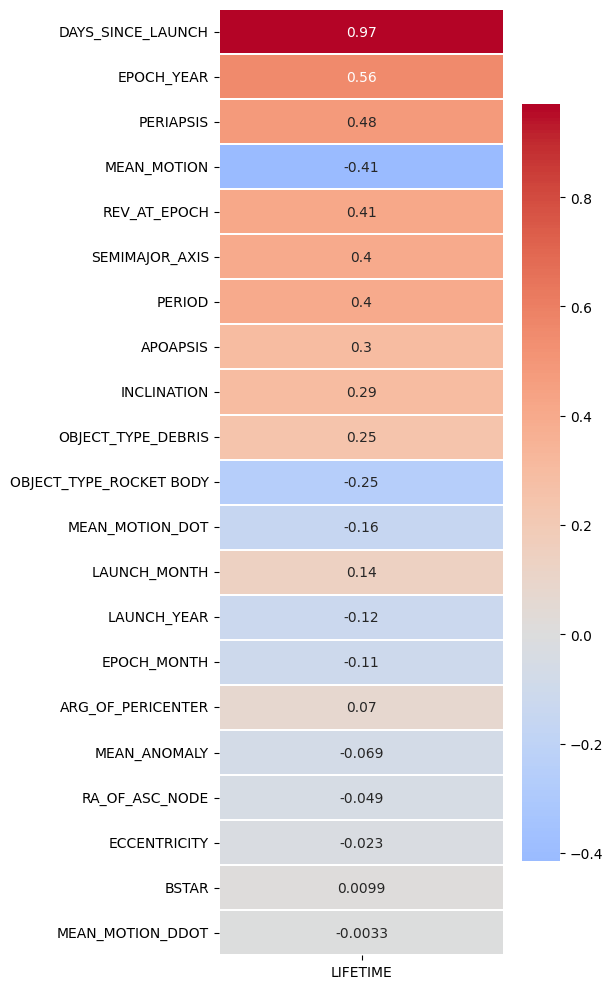

In [95]:
# 2. Heatmap for correlation of all features with the 'LIFETIME' column
print('Correlation of all features with the LIFETIME column:')
lifetime_corr = corr_matrix[['LIFETIME']].drop(['LIFETIME', 'REMAINING_LIFETIME'], axis=0)
lifetime_corr = lifetime_corr.reindex(lifetime_corr['LIFETIME'].abs().sort_values(ascending=False).index)

plt.figure(figsize=(6, 10))
sns.heatmap(lifetime_corr, annot=True, cmap="coolwarm", center=0,
            linewidths=0.2, cbar_kws={"shrink": 0.8})
plt.tight_layout()
plt.show()

Correlation of all features with the REMAINING_LIFETIME column:


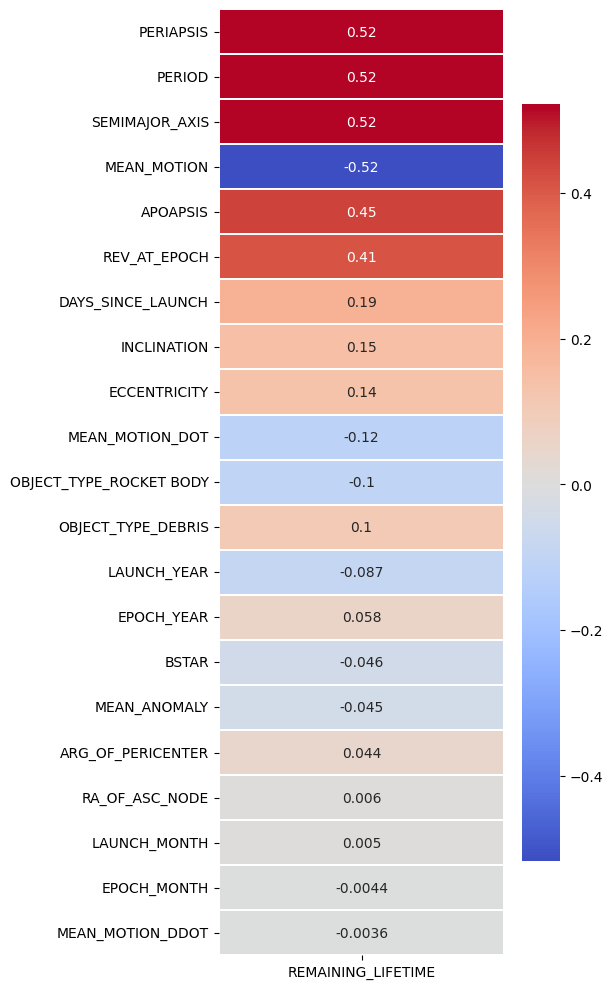

In [96]:
# 3. Heatmap for correlation of all features with the 'REMAINING_LIFETIME' column
print('Correlation of all features with the REMAINING_LIFETIME column:')
remlifetime_corr = corr_matrix[['REMAINING_LIFETIME']].drop(['LIFETIME', 'REMAINING_LIFETIME'], axis=0)
remlifetime_corr = remlifetime_corr.reindex(remlifetime_corr['REMAINING_LIFETIME'].abs().sort_values(ascending=False).index)

plt.figure(figsize=(6, 10))
sns.heatmap(remlifetime_corr, annot=True, cmap="coolwarm", center=0,
            linewidths=0.2, cbar_kws={"shrink": 0.8})
plt.tight_layout()
plt.show()

/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_3168/1654945495.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Adjust layout to make space for the color bar


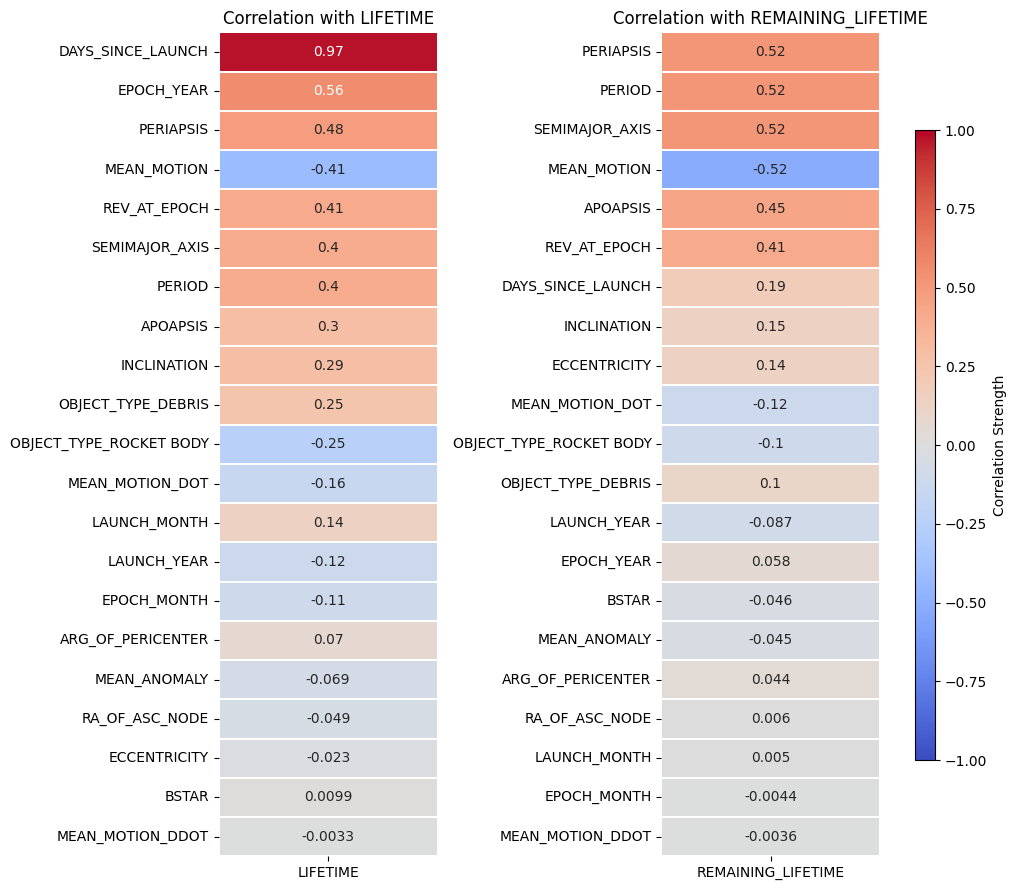

In [97]:
# display correlations of Lifetime and Remaining Lifetime next to each other with only one legend
fig, ax = plt.subplots(1, 2, figsize=(10, 9))

# Create the heatmaps without individual color bars
sns.heatmap(lifetime_corr, annot=True, cmap="coolwarm", center=0,
            linewidths=0.2, cbar=False, ax=ax[0], vmin=-1, vmax=1)
sns.heatmap(remlifetime_corr, annot=True, cmap="coolwarm", center=0,
            linewidths=0.2, cbar=False, ax=ax[1], vmin=-1, vmax=1)

# Add a single color bar for both heatmaps
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # Adjust position and size as needed
norm = plt.Normalize(vmin=-1, vmax=1)  # Normalize the color bar to correlation range
sm = plt.cm.ScalarMappable(cmap="coolwarm", norm=norm)
sm.set_array([])
fig.colorbar(sm, cax=cbar_ax, orientation="vertical", label="Correlation Strength")

# Set titles for the subplots
ax[0].set_title('Correlation with LIFETIME')
ax[1].set_title('Correlation with REMAINING_LIFETIME')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Adjust layout to make space for the color bar
plt.show()

Feature Correlation of Site and Country

In [142]:
# drop all columns except the ones starting with Site or Country, Lifetime and Remaining Lifetime
debrisCorrSiteCountry_df = debrisCorrAll_df.filter(regex='^(COUNTRY|SITE|LIFETIME|REMAINING_LIFETIME)')

In [143]:
# create correlation matrix
corr_matrixSiteCountry = debrisCorrSiteCountry_df.corr()

In [147]:
# sort correlations with Lifetime descending
sorted_corrSiteCountry = corr_matrixSiteCountry['LIFETIME'].sort_values(ascending=False)
sorted_corrSiteCountry

LIFETIME              1.000000
REMAINING_LIFETIME    0.420502
SITE_PKMTR            0.222215
SITE_TSC              0.063255
SITE_AFWTR            0.062004
COUNTRY_US            0.061563
COUNTRY_CHBZ          0.037139
COUNTRY_ORB           0.036911
SITE_ERAS             0.021762
SITE_HGSTR            0.020119
COUNTRY_CA            0.008252
COUNTRY_ESA           0.006875
COUNTRY_PRC           0.006735
COUNTRY_TWN           0.005845
SITE_NSC              0.000449
COUNTRY_SKOR          0.000449
COUNTRY_ISS           0.000340
SITE_WOMRA           -0.000799
SITE_OREN            -0.002054
COUNTRY_NKOR         -0.002318
SITE_YUN             -0.002318
SITE_CAS             -0.002329
COUNTRY_UK           -0.002618
SITE_SCSLA           -0.004842
SITE_KODAK           -0.004866
COUNTRY_ESRO         -0.006275
SITE_VOSTO           -0.006892
SITE_SADOL           -0.007765
SITE_SMTS            -0.008462
SITE_SNMLP           -0.008710
SITE_SEM             -0.009604
SITE_YAVNE           -0.012265
COUNTRY_

In [148]:
# sort correlations with Remaining Lifetime descending
sorted_corrSiteCountry = corr_matrixSiteCountry['REMAINING_LIFETIME'].sort_values(ascending=False)
sorted_corrSiteCountry

REMAINING_LIFETIME    1.000000
LIFETIME              0.420502
COUNTRY_US            0.186830
SITE_TSC              0.156665
SITE_AFWTR            0.138668
COUNTRY_PRC           0.113236
SITE_AFETR            0.083871
COUNTRY_CHBZ          0.054561
SITE_HGSTR            0.031259
SITE_OREN             0.014959
SITE_WOMRA            0.012064
COUNTRY_UK            0.011610
COUNTRY_FR            0.010893
COUNTRY_SKOR          0.009075
SITE_NSC              0.009075
SITE_YUN              0.006596
COUNTRY_NKOR          0.006596
SITE_FRGUI            0.002566
SITE_SADOL            0.001368
COUNTRY_ESRO          0.001032
SITE_CAS              0.000978
SITE_SVOB             0.000150
SITE_SRI             -0.000597
COUNTRY_IND          -0.000597
SITE_WRAS            -0.001068
SITE_SNMLP           -0.001445
COUNTRY_CA           -0.002607
SITE_SCSLA           -0.002776
SITE_KODAK           -0.002877
COUNTRY_ESA          -0.003338
COUNTRY_TWN          -0.003878
SITE_SMTS            -0.003995
SITE_VOS

## 4. Analysis of Individual Features 
In order to explain certain insteresting feature correlations 

BStar

In [108]:
# statistics of BStar
print(debris_df['BSTAR'].describe())

count    23022.000000
mean         0.008866
std          0.059784
min         -0.609100
25%          0.000104
50%          0.000958
75%          0.003936
max          2.511400
Name: BSTAR, dtype: float64


In [130]:
# show how many 0 values for BStar
print("Objects with BSTAR = 0: ", debris_df[debris_df['BSTAR'] == 0].shape[0])
print("-> ", round(debris_df[debris_df['BSTAR'] == 0].shape[0] / debris_df.shape[0] * 100, 2), "%")

Objects with BSTAR = 0:  4481
->  19.46 %


Boxplot of BStar:


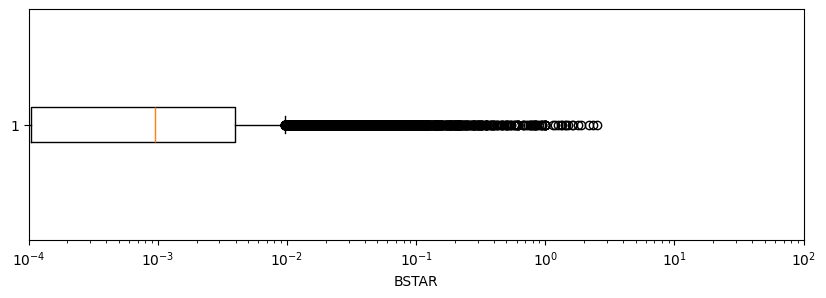

In [139]:
# boxplot of BStar
print('Boxplot of BStar:')
plt.figure(figsize=(10, 3))
plt.style.use('default')
plt.boxplot(debris_df['BSTAR'], vert=False)
plt.xlabel('BSTAR')
plt.xscale('log')
plt.xlim(0.0001, 100)
plt.show()

Mean Motion Double Dot

In [113]:
# statistics of Mean Motion DDot
print(debris_df['MEAN_MOTION_DDOT'].describe())

count    2.302200e+04
mean     1.181151e-01
std      1.353479e+01
min     -5.513600e-05
25%      0.000000e+00
50%      0.000000e+00
75%      3.856075e-07
max      1.994400e+03
Name: MEAN_MOTION_DDOT, dtype: float64


In [140]:
# show how many 0 values for Mean Motion DDot
print("Objects with MEAN_MOTION_DDOT = 0: ", debris_df[debris_df['MEAN_MOTION_DDOT'] == 0].shape[0])
print("-> ", round(debris_df[debris_df['MEAN_MOTION_DDOT'] == 0].shape[0] / debris_df.shape[0] * 100, 2), "%")

Objects with MEAN_MOTION_DDOT = 0:  16387
->  71.18 %


Epoch Year

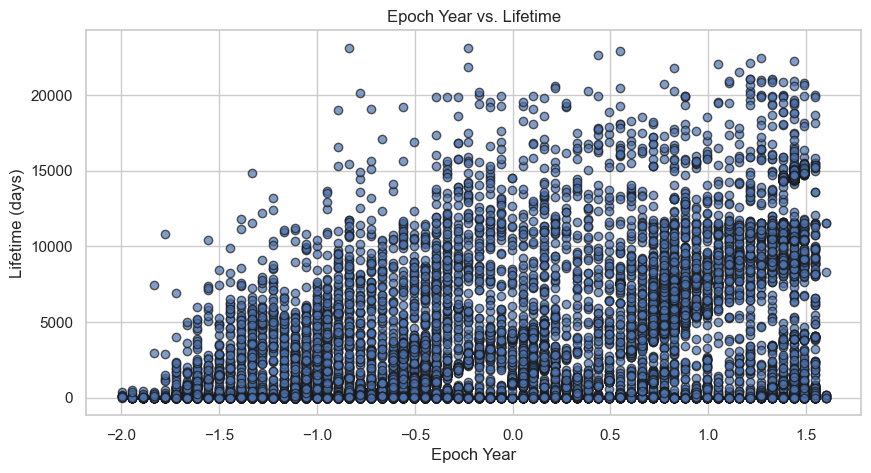

In [119]:
# plot Epoch Year vs. Lifetime
plt.figure(figsize=(10, 5))
plt.scatter(debrisCorr_df['EPOCH_YEAR'], debrisCorr_df['LIFETIME'], alpha=0.7, edgecolors='k')
plt.xlabel('Epoch Year')
plt.ylabel('Lifetime (days)')
plt.title('Epoch Year vs. Lifetime')
plt.grid(True)
plt.show()